# Tamaño de las cajas de ACOLITE (`scene_box`)

Replica la lógica de `tools/ac/run_acolite.py` (`split_points` + `scene_box`) sobre
`data/nuevos/matchups_registros_finales_geometria.geojson` y calcula el tamaño en km de cada caja.

- Agrupamiento: single linkage, puntos a menos de `CLUSTER_KM` comparten caja.
- Caja: bounding box lat/lon de los puntos + `MARGIN` grados por lado.
- Km: alto = Δlat·111,19; ancho = Δlon·111,19·cos(lat media). Aproximado (esfera).

In [1]:
import sys
from pathlib import Path

_REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(_REPO_ROOT))
from core.ac_tools import scene_box, split_points

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
GEOJSON = ROOT / "data" / "nuevos" / "matchups_registros_finales_geometria.geojson"
CLUSTER_KM = 20      # igual que run_acolite.py
MARGIN = 0.05        # grados, igual que --margin
KM_DEG = 111.19

In [2]:
gdf = gpd.read_file(GEOJSON)
to_wgs84 = Transformer.from_crs(gdf.crs or "EPSG:32721", "EPSG:4326", always_xy=True)
lon, lat = to_wgs84.transform(gdf.geometry.x.values, gdf.geometry.y.values)
pts = pd.DataFrame({"pass_id": gdf["pass_id"].values, "lat": lat, "lon": lon,
                    "x": gdf.geometry.x.values, "y": gdf.geometry.y.values})
print(f"{len(pts)} puntos, {pts.pass_id.nunique()} escenas, CRS {gdf.crs}")

2957 puntos, 518 escenas, CRS EPSG:32721


In [3]:
rows = []
for pid, p in pts.groupby("pass_id"):
    parts = split_points(p, CLUSTER_KM)
    for i, g in enumerate(parts, 1):
        s, w, n, e = scene_box(g, MARGIN)
        alto = (n - s) * KM_DEG
        ancho = (e - w) * KM_DEG * np.cos(np.radians((n + s) / 2))
        rows.append(dict(pass_id=pid, parte=i, n_partes=len(parts), n_puntos=len(g),
                         alto_km=alto, ancho_km=ancho, area_km2=alto * ancho))
boxes = pd.DataFrame(rows)
print(f"{len(boxes)} cajas; escenas partidas en varias cajas: {(boxes.groupby('pass_id').n_partes.first() > 1).sum()}")

537 cajas; escenas partidas en varias cajas: 16


## Resumen

In [4]:
boxes[["n_puntos", "alto_km", "ancho_km", "area_km2"]].describe(percentiles=[.5, .9, .99]).round(1)

,n_puntos,alto_km,ancho_km,area_km2
count,537.0,537.0,537.0,537.0
mean,5.5,15.4,17.2,290.1
std,7.6,4.4,10.0,211.8
min,1.0,11.1,9.1,101.5
50%,4.0,12.8,17.9,287.6
90%,9.0,20.4,30.1,683.0
99%,46.6,22.7,45.3,818.6
max,54.0,22.7,45.3,818.6


In [5]:
for lim in (30, 50, 90):
    print(f"cajas con algún lado > {lim} km: {((boxes.alto_km > lim) | (boxes.ancho_km > lim)).sum()}")

cajas con algún lado > 30 km: 65
cajas con algún lado > 50 km: 0
cajas con algún lado > 90 km: 0


## Las más grandes

In [6]:
pd.set_option("display.max_colwidth", None)
boxes.sort_values("area_km2", ascending=False).head(15)[["pass_id", "alto_km", "ancho_km", "area_km2"]].round(1)

,pass_id,alto_km,ancho_km,area_km2
421,S2B_MSIL1C_20221206T133829_N0510_R124_T21HWD_20240707T235442,18.1,45.3,818.6
418,S2B_MSIL1C_20221106T133839_N0510_R124_T21HWD_20240731T040657,18.1,45.3,818.6
383,S2B_MSIL1C_20211201T134209_N0500_R124_T21HWD_20221226T061600,18.1,45.3,818.6
205,S2A_MSIL1C_20221002T133841_N0510_R124_T21HWD_20240718T024532,18.1,45.3,818.6
202,S2A_MSIL1C_20220714T133851_N0510_R124_T21HWD_20240715T171717,18.1,45.3,818.6
220,S2A_MSIL1C_20230301T133831_N0510_R124_T21HWD_20240817T072157,18.1,45.3,818.6
189,S2A_MSIL1C_20220316T134211_N0510_R124_T21HWD_20240529T082900,18.1,45.3,818.6
182,S2A_MSIL1C_20220214T134211_N0510_R124_T21HWD_20240521T052904,18.1,45.3,818.6
163,S2A_MSIL1C_20211106T134211_N0500_R124_T21HWD_20230101T052555,18.1,45.3,818.6
160,S2A_MSIL1C_20211007T134221_N0500_R124_T21HWD_20230113T095609,18.1,45.3,818.6


## Distribución

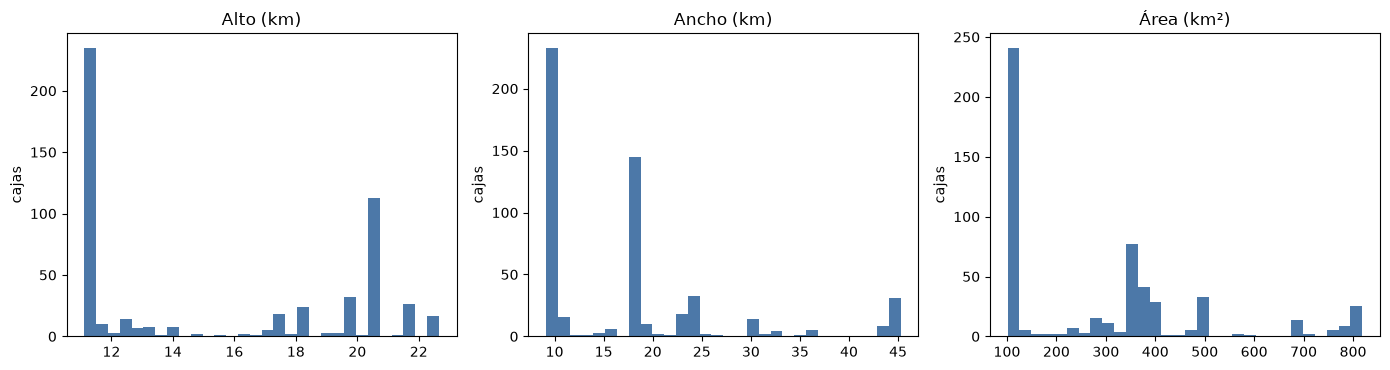

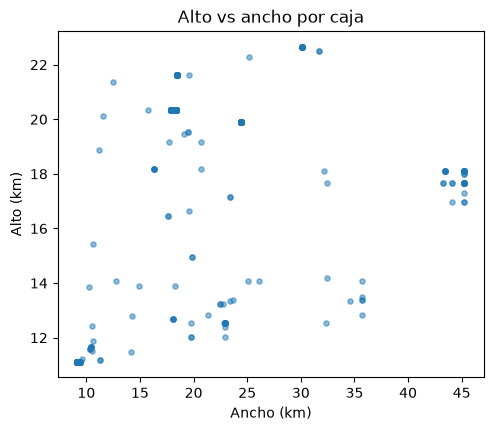

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c, t in zip(ax, ["alto_km", "ancho_km", "area_km2"], ["Alto (km)", "Ancho (km)", "Área (km²)"]):
    a.hist(boxes[c], bins=30, color="#4C78A8"); a.set_title(t); a.set_ylabel("cajas")
plt.tight_layout()

fig, a = plt.subplots(figsize=(5.5, 4.5))
a.scatter(boxes.ancho_km, boxes.alto_km, s=14, alpha=.5)
a.set_xlabel("Ancho (km)"); a.set_ylabel("Alto (km)"); a.set_title("Alto vs ancho por caja")
plt.show()

## Guardar

In [8]:
OUT = ROOT / "data" / "nuevos" / "scene_box_tamanios.csv"
boxes[["pass_id", "alto_km", "ancho_km", "area_km2"]].round(2).to_csv(OUT, index=False)
print(f"{len(boxes)} cajas -> {OUT}")

537 cajas -> /home/enzotrindade/ProyectoAA/data/nuevos/scene_box_tamanios.csv
